# Tropical cyclone intensity: a visual scientific analysis

In this phase we have answered to the three following questions about the observations from 2010–2025:

1. How does cyclone intensity differ across ocean basins?
2. How are intensity, central pressure, and observed track duration related?
3. How does cyclone intensity vary from year to year?

## Data and methodology

For each `SID`, peak wind is the maximum available `USA_WIND`, minimum pressure is the minimum available `USA_PRES`, and observed duration is the interval from the first to last retained timestamp. Duration is a **track span**, not necessarily physical lifetime. USA winds are one-minute sustained winds in knots; pressure is in hPa. We keep missing measurements missing and never substitute WMO values, whose wind averaging conventions vary. The representative basin is the one containing the most observations for that cyclone (alphabetical tie break). The first retained calendar year assigns a cyclone to one year. These choices match the EDA's storm-level approach.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("datasets/processed/cyclones_2010_2025.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["ISO_TIME"], keep_default_na=False, na_values=[""])
required = {"SID", "ISO_TIME", "SEASON", "BASIN", "TRACK_TYPE", "USA_WIND", "USA_PRES"}
BASIN_ORDER = ["NA", "EP", "WP", "NI", "SI", "SP", "SA"]
MAJOR_BASINS = BASIN_ORDER[:-1]
BASIN_COLORS = dict(zip(BASIN_ORDER, sns.color_palette("colorblind", len(BASIN_ORDER))))
sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=.82)
plt.rcParams.update({"figure.dpi":115,"axes.spines.top":False,"axes.spines.right":False,"grid.alpha":.22,"axes.titleweight":"bold"})
ordered = df.sort_values(["SID", "ISO_TIME"])
storm_df = ordered.groupby("SID", sort=False).agg(first=("ISO_TIME","first"),last=("ISO_TIME","last"),season=("SEASON","first"),max_wind=("USA_WIND","max"),min_pressure=("USA_PRES","min"),all_main=("TRACK_TYPE",lambda values:values.eq("main").all()))
storm_df["duration_days"] = (storm_df["last"]-storm_df["first"]).dt.total_seconds()/86400
storm_df["first_year"] = storm_df["first"].dt.year
basin_visits = ordered.groupby(["SID","BASIN"]).size().rename("fixes").reset_index().sort_values(["SID","fixes","BASIN"],ascending=[True,False,True])
storm_df["basin"] = basin_visits.drop_duplicates("SID").set_index("SID")["BASIN"]

print(f"Cyclones: {len(storm_df):,}; with both USA intensity measures: {storm_df[['max_wind','min_pressure']].dropna().shape[0]:,}")
print("Measured wind by basin:",storm_df.groupby("basin").max_wind.count().reindex(BASIN_ORDER).to_dict())
print(f"Storms assigned to partial season 2026: {storm_df.season.eq(2026).sum()}")


Cyclones: 1,667; with both USA intensity measures: 1,538
Measured wind by basin: {'NA': 289, 'EP': 318, 'WP': 451, 'NI': 90, 'SI': 248, 'SP': 140, 'SA': 2}
Storms assigned to partial season 2026: 12


The archive contains **1,667 cyclones**; **1,538** have both a USA peak wind and minimum pressure. South Atlantic has only two storms: it is omitted from most comparative figures and shown with an explicit small-sample warning in the intensity-category infographic. North Indian wind coverage is much lower (90 measured of 166 assigned storms) than in the North Atlantic or East Pacific (complete coverage). Basin patterns among measured storms may therefore reflect selection as well as meteorology.


## 1. How does intensity differ across ocean basins?

The two raincloud panels show storm-level intensity distributions. Each half-density shape is scaled within its basin, so its height shows **distribution shape**, not the number of storms; sample sizes appear beside the basin codes. The boxes show medians and quartiles, and the jittered dots show individual cyclones. Peak wind and minimum pressure are related intensity indicators, but their extrema can occur at different times in a storm.


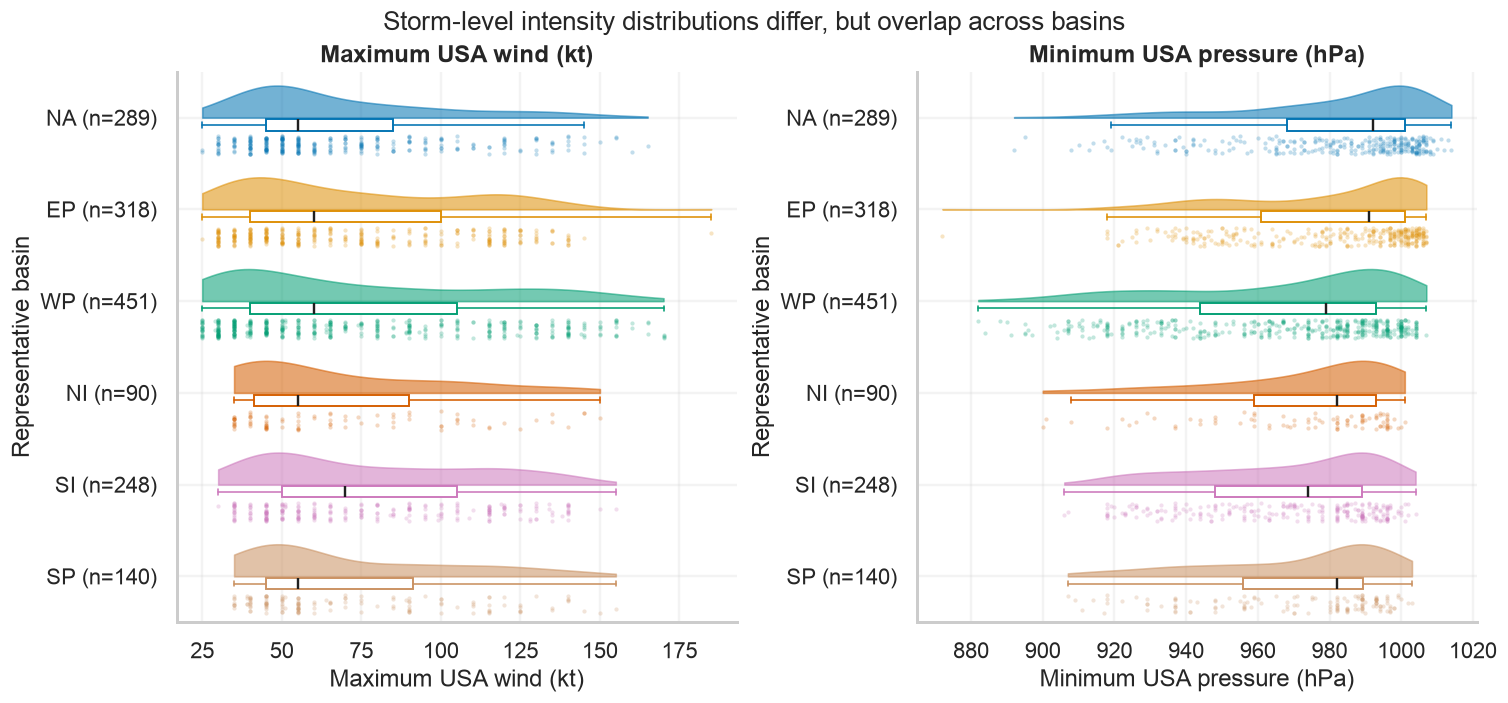

In [3]:
measured = storm_df.loc[storm_df.basin.isin(MAJOR_BASINS)].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
rng = np.random.default_rng(42)
for ax, variable, label in zip(axes, ["max_wind", "min_pressure"], ["Maximum USA wind (kt)", "Minimum USA pressure (hPa)"]):
    part = measured.dropna(subset=[variable])
    sizes = part.groupby("basin").size().reindex(MAJOR_BASINS)
    for i, basin in enumerate(MAJOR_BASINS):
        values = part.loc[part.basin.eq(basin), variable].to_numpy()
        color = BASIN_COLORS[basin]
        violin = ax.violinplot(values, positions=[i], orientation="horizontal", side="low", widths=.7, showextrema=False)
        violin["bodies"][0].set(facecolor=color, edgecolor=color, alpha=.55, linewidth=1)
        ax.boxplot(values, positions=[i + .08], orientation="horizontal", widths=.12, patch_artist=True, showfliers=False, manage_ticks=False,
                   boxprops={"facecolor":"white", "edgecolor":color, "linewidth":1.2}, medianprops={"color":"#202020", "linewidth":1.5},
                   whiskerprops={"color":color, "linewidth":1}, capprops={"color":color, "linewidth":1})
        ax.scatter(values, rng.uniform(i + .20, i + .40, len(values)), s=7, alpha=.24, color=color, linewidths=0, rasterized=True)
    ax.set(ylabel="Representative basin", xlabel=label, title=label)
    ax.set_yticks(np.arange(len(MAJOR_BASINS)), labels=[f"{b} (n={sizes[b]})" for b in MAJOR_BASINS])
    ax.set_ylim(len(MAJOR_BASINS) - .5, -.5)
fig.suptitle("Storm-level intensity distributions differ, but overlap across basins", fontsize=16)
plt.show()


The South Indian basin has the highest median measured peak wind (**70 kt**) and a lower median minimum pressure (**974 hPa**) than the North Atlantic (**55 kt; 992 hPa**). Yet the distributions overlap widely: basin alone does not determine a cyclone's intensity. The North Indian raincloud rests on only **90** wind-measured storms, so its apparent shape is less representative of all assigned storms.


A second view asks how often measured cyclones reach different one-minute wind ranges. The thresholds correspond to below hurricane strength (<64 kt), category 1–2 range (64–95 kt), and category 3+ range (≥96 kt). Each spoke shows the percentage **among storms with a USA wind measurement** in that basin; the three percentages sum to 100% for each basin. South Atlantic is shown for completeness but has only two measured storms. Filled polygon area is not a statistic.


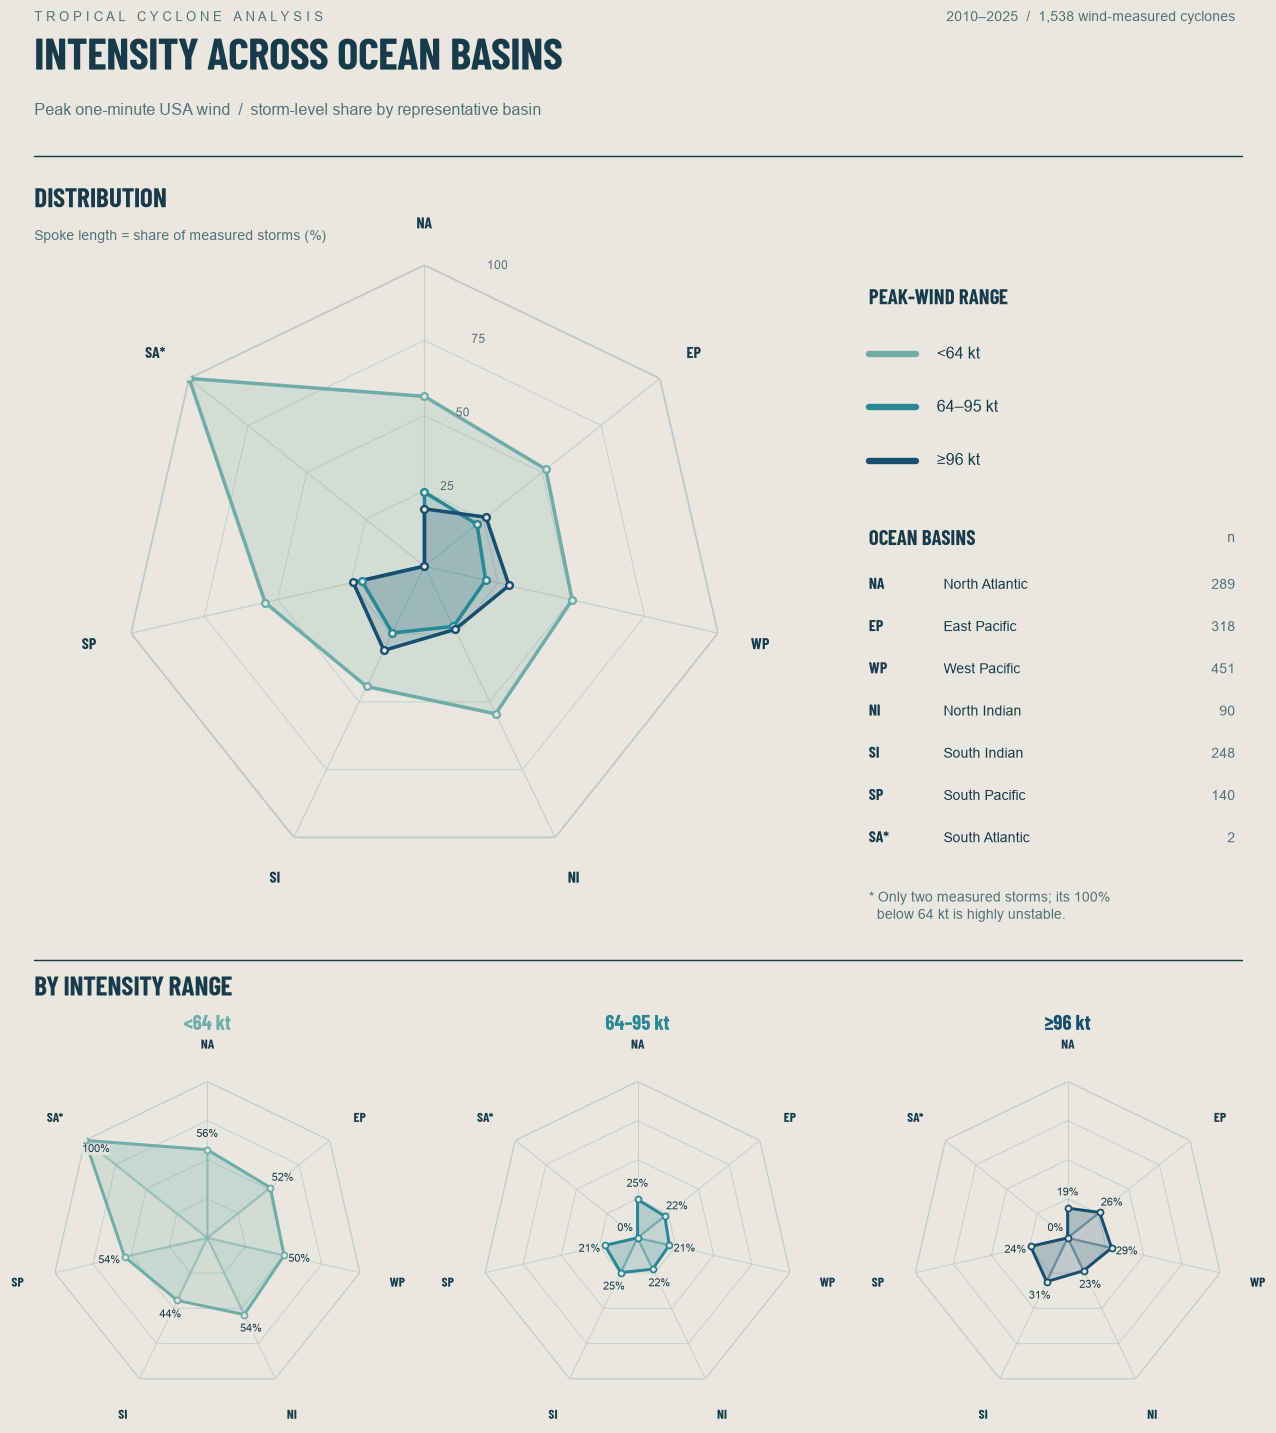

In [10]:
# One cyclone per SID; storms without a measured USA peak wind are excluded from the denominator.
wind_storms = storm_df.loc[storm_df.basin.isin(BASIN_ORDER)].dropna(subset=["max_wind"]).copy()
band_labels = ["<64 kt", "64–95 kt", "≥96 kt"]
wind_storms["wind_band"] = pd.cut(
    wind_storms.max_wind, bins=[-np.inf, 64, 96, np.inf], right=False, labels=band_labels
)
band_counts = pd.crosstab(wind_storms.basin, wind_storms.wind_band).reindex(
    index=BASIN_ORDER, columns=band_labels, fill_value=0
)
basin_n = band_counts.sum(axis=1)
band_share = band_counts.div(basin_n, axis=0).mul(100)

# Ocean palette and polygonal grid echo the reference's quiet editorial geometry.
paper, ink, secondary, grid = "#E9E7DF", "#173B4B", "#54707A", "#B9C8C8"
colors = {"<64 kt": "#70ADA9", "64–95 kt": "#2A8795", "≥96 kt": "#174F70"}
angles = np.linspace(0, 2 * np.pi, len(BASIN_ORDER), endpoint=False)
closed_angles = np.r_[angles, angles[0]]

def style_radar(ax, *, large=False):
    ax.set_facecolor(paper)
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_ylim(0, 100)
    ax.set_xticks(angles)
    ax.set_xticklabels(["SA*" if b == "SA" else b for b in BASIN_ORDER],
                       color=ink, fontsize=10 if large else 8.5,
                       fontfamily="Barlow Condensed", fontweight="bold")
    ax.tick_params(axis="x", pad=11 if large else 8)
    ax.set_yticks([])
    ax.xaxis.grid(True, color=grid, linewidth=.8 if large else .65, alpha=.72)
    ax.spines["polar"].set_visible(False)
    for radius in [25, 50, 75, 100]:
        ax.plot(closed_angles, [radius] * len(closed_angles), color=grid,
                linewidth=1.1 if radius == 100 and large else .7,
                alpha=.95 if radius == 100 else .65, zorder=1)
    if large:
        for radius in [25, 50, 75, 100]:
            ax.text(np.deg2rad(12), radius, str(radius), color=secondary,
                    fontsize=7.5, ha="left", va="bottom", zorder=6)

fig = plt.figure(figsize=(11.8, 13.6), facecolor=paper)
fig.text(.055, .965, "T R O P I C A L   C Y C L O N E   A N A L Y S I S",
         color=secondary, fontsize=8)
fig.text(.055, .934, "INTENSITY ACROSS OCEAN BASINS", color=ink,
         fontsize=28, fontweight="bold", fontfamily="Barlow Condensed")
fig.text(.055, .905,
         "Peak one-minute USA wind  /  storm-level share by representative basin",
         color=secondary, fontsize=10)
fig.text(.94, .965, "2010–2025  /  1,538 wind-measured cyclones",
         color=secondary, fontsize=8.5, ha="right")
fig.add_artist(plt.Line2D([.055, .945], [.879, .879], transform=fig.transFigure,
                          color=ink, linewidth=.9))

fig.text(.055, .846, "DISTRIBUTION", color=ink, fontsize=17, fontweight="bold",
         fontfamily="Barlow Condensed")
fig.text(.055, .825, "Spoke length = share of measured storms (%)", color=secondary,
         fontsize=9)

main_ax = fig.add_axes([.075, .424, .535, .385], projection="polar")
style_radar(main_ax, large=True)
for band in band_labels:
    values = band_share[band].to_numpy()
    closed_values = np.r_[values, values[0]]
    main_ax.fill(closed_angles, closed_values, color=colors[band], alpha=.17, zorder=2)
    main_ax.plot(closed_angles, closed_values, color=colors[band], linewidth=2.2,
                 solid_joinstyle="round", zorder=3)
    main_ax.scatter(angles, values, s=18, facecolor=paper, edgecolor=colors[band],
                    linewidth=1.45, zorder=4)

# Compact right-side key follows the information hierarchy of the reference.
fig.text(.67, .784, "PEAK-WIND RANGE", color=ink, fontsize=13,
         fontweight="bold", fontfamily="Barlow Condensed")
for y, band in zip([.752, .718, .684], band_labels):
    fig.add_artist(plt.Line2D([.67, .705], [y, y], transform=fig.transFigure,
                              color=colors[band], linewidth=4, solid_capstyle="round"))
    fig.text(.72, y, band, va="center", color=ink, fontsize=10)
fig.text(.67, .63, "OCEAN BASINS", color=ink, fontsize=13,
         fontweight="bold", fontfamily="Barlow Condensed")
fig.text(.94, .632, "n", color=secondary, fontsize=9, ha="right")
basin_names = {
    "NA": "North Atlantic", "EP": "East Pacific", "WP": "West Pacific",
    "NI": "North Indian", "SI": "South Indian", "SP": "South Pacific",
    "SA": "South Atlantic",
}
for i, basin in enumerate(BASIN_ORDER):
    y = .602 - i * .027
    code = "SA*" if basin == "SA" else basin
    fig.text(.67, y, code, color=ink, fontsize=10, fontweight="bold",
             fontfamily="Barlow Condensed")
    fig.text(.725, y, basin_names[basin], color=ink, fontsize=9)
    fig.text(.94, y, f"{basin_n[basin]}", color=secondary, fontsize=9, ha="right")
fig.text(.67, .391, "* Only two measured storms; its 100%\n  below 64 kt is highly unstable.",
         color=secondary, fontsize=8.5, linespacing=1.35)

fig.add_artist(plt.Line2D([.055, .945], [.365, .365], transform=fig.transFigure,
                          color=ink, linewidth=.9))
fig.text(.055, .342, "BY INTENSITY RANGE", color=ink, fontsize=17,
         fontweight="bold", fontfamily="Barlow Condensed")

for left, band in zip([.055, .372, .689], band_labels):
    ax = fig.add_axes([left, .087, .255, .20], projection="polar")
    style_radar(ax)
    values = band_share[band].to_numpy()
    # Subtle tonal facets recall the lower radial diagrams without changing the data.
    for i in range(len(angles)):
        j = (i + 1) % len(angles)
        next_angle = angles[j] if j else 2 * np.pi
        ax.fill([angles[i], next_angle, angles[i]], [values[i], values[j], 0],
                color=colors[band], alpha=.19 if i % 2 else .27, zorder=2)
    ax.plot(closed_angles, np.r_[values, values[0]], color=colors[band],
            linewidth=1.85, solid_joinstyle="round", zorder=3)
    ax.scatter(angles, values, s=14, facecolor=paper, edgecolor=colors[band],
               linewidth=1.1, zorder=4)
    for angle, value in zip(angles, values):
        label_radius = value - 9 if value >= 88 else max(value + 10, 9)
        ax.text(angle, label_radius, f"{value:.0f}%", ha="center", va="center",
                color=ink, fontsize=7.1, zorder=5,
                bbox={"facecolor": paper, "edgecolor": "none", "pad": .15, "alpha": .87})
    fig.text(left + .1275, .320, band, ha="center", color=colors[band],
             fontsize=13, fontweight="bold", fontfamily="Barlow Condensed")
plt.show()


The ≥96 kt share is largest in the **South Indian basin (77/248, 31%)** and is also substantial in the West Pacific (**130/451, 29%**). The North Atlantic share is **55/289 (19%)**. These are conditional on measured USA wind; regional differences in coverage and archive practices limit a direct global-risk interpretation. The 64 and 96 kt cutoffs use US one-minute wind definitions, rather than the mixed source-specific WMO wind fields.


## 2. What relationships connect intensity, pressure, and duration?

All three plots use one row per cyclone. Pearson's correlation coefficient (r) summarizes the overall linear association. It is sensitive to outliers and can miss curvature, so the full point cloud remains important. The plotted trend is a **median within broad bins**, included to guide the eye rather than to claim a predictive model. Correlation is descriptive and does not imply causation.


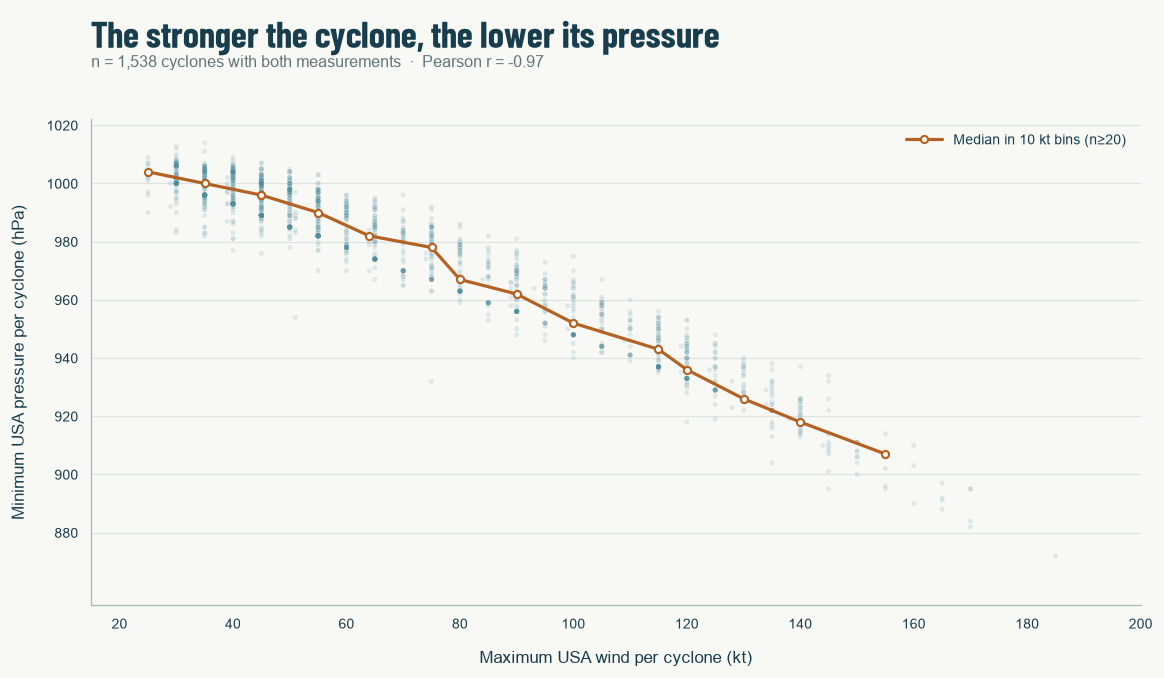

In [4]:
wind_pressure = storm_df[["max_wind","min_pressure"]].dropna()
r_wp = wind_pressure.max_wind.corr(wind_pressure.min_pressure, method="pearson")
wind_bins = pd.cut(wind_pressure.max_wind, np.arange(10, 201, 10), right=False)
wind_trend = wind_pressure.groupby(wind_bins, observed=True).agg(
    wind=("max_wind", "median"), pressure=("min_pressure", "median"), n=("min_pressure", "size")
)
wind_trend = wind_trend.loc[wind_trend.n >= 20]

paper, ink, muted, point, median, grid = (
    "#F8F8F5", "#183D4D", "#60747A", "#4D8B9D", "#B36224", "#D8E0DF"
)
fig, ax = plt.subplots(figsize=(10.8, 6.5), facecolor=paper)
fig.subplots_adjust(left=.115, right=.96, bottom=.16, top=.81)
ax.set_facecolor(paper)

# The raw storm-level observations remain unshifted; lighter marks expose overlap.
ax.scatter(wind_pressure.max_wind, wind_pressure.min_pressure,
           s=10, alpha=.14, color=point, edgecolors="none", rasterized=True,
           zorder=2)
ax.plot(wind_trend.wind, wind_trend.pressure, color=median, linewidth=2,
        marker="o", markersize=4.5, markerfacecolor=paper,
        markeredgecolor=median, markeredgewidth=1.3,
        label="Median in 10 kt bins (n≥20)", zorder=3)

ax.set(xlim=(15, 198), ylim=(855, 1022))
ax.set_xticks(np.arange(20, 201, 20))
ax.set_yticks(np.arange(880, 1021, 20))
ax.set_xlabel("Maximum USA wind per cyclone (kt)", color=ink, fontsize=10.5, labelpad=12)
ax.set_ylabel("Minimum USA pressure per cyclone (hPa)", color=ink, fontsize=10.5, labelpad=12)
ax.grid(False)
ax.yaxis.grid(True, color=grid, linewidth=.75, alpha=.82)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#A9B9BA")
    ax.spines[spine].set_linewidth(.8)
ax.tick_params(axis="both", which="both", length=0, pad=8,
               labelcolor=ink, labelsize=9)

fig.suptitle("The stronger the cyclone, the lower its pressure",
             x=.115, y=.955, ha="left", color=ink, fontsize=23,
             fontweight="bold", fontfamily="Barlow Condensed")
fig.text(.115, .88, f"n = {len(wind_pressure):,} cyclones with both measurements  ·  Pearson r = {r_wp:.2f}",
         color=muted, fontsize=10)
ax.legend(loc="upper right", frameon=False, labelcolor=ink,
          fontsize=9, handlelength=2.5, borderaxespad=.6)
plt.show()


The storm-level association is strongly inverse (**Pearson r≈−0.97**, 1,538 storms). Wind and pressure both describe intensity, so this is physically expected rather than an independent discovery. A cyclone's maximum wind and minimum pressure can occur at different timestamps; the dots compare **track summaries**, not simultaneous atmospheric states.


Observed track duration is next compared with peak wind. The broad-bin median line reveals whether the central tendency changes while keeping the many individual cyclone points visible.


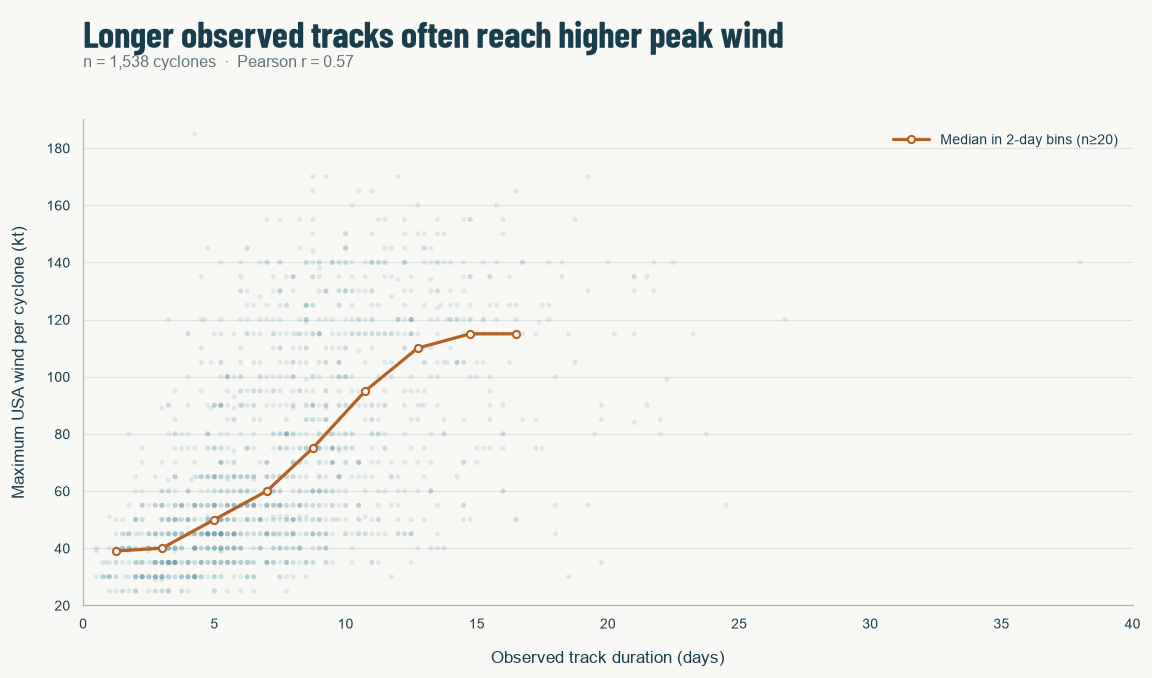

In [5]:
duration_wind = storm_df[["duration_days","max_wind"]].dropna()
r_dw = duration_wind.duration_days.corr(duration_wind.max_wind,method="pearson")
duration_bins = pd.cut(duration_wind.duration_days,np.arange(0,41,2),right=False)
duration_wind_trend = duration_wind.groupby(duration_bins,observed=True).agg(duration=("duration_days","median"),wind=("max_wind","median"),n=("max_wind","size"))
duration_wind_trend = duration_wind_trend.loc[duration_wind_trend.n>=20]
paper, ink, muted, point, median, grid = (
    "#F8F8F5", "#183D4D", "#60747A", "#4D8B9D", "#B36224", "#D8E0DF"
)
fig, ax = plt.subplots(figsize=(10.8, 6.5), facecolor=paper)
fig.subplots_adjust(left=.115, right=.96, bottom=.16, top=.81)
ax.set_facecolor(paper)

ax.scatter(duration_wind.duration_days, duration_wind.max_wind, s=10, alpha=.14,
           color=point, edgecolors="none", rasterized=True, zorder=2)
ax.plot(duration_wind_trend.duration, duration_wind_trend.wind, color=median,
        linewidth=2, marker="o", markersize=4.5, markerfacecolor=paper,
        markeredgecolor=median, markeredgewidth=1.3,
        label="Median in 2-day bins (n≥20)", zorder=3)

ax.set(xlim=(0, 40), ylim=(20, 190))
ax.set_xticks(np.arange(0, 41, 5))
ax.set_yticks(np.arange(20, 181, 20))
ax.set_xlabel("Observed track duration (days)", color=ink, fontsize=10.5, labelpad=12)
ax.set_ylabel("Maximum USA wind per cyclone (kt)", color=ink, fontsize=10.5, labelpad=12)
ax.grid(False)
ax.yaxis.grid(True, color=grid, linewidth=.75, alpha=.82)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#A9B9BA")
    ax.spines[spine].set_linewidth(.8)
ax.tick_params(axis="both", which="both", length=0, pad=8,
               labelcolor=ink, labelsize=9)

fig.suptitle("Longer observed tracks often reach higher peak wind", x=.115, y=.955, ha="left",
             color=ink, fontsize=23, fontweight="bold", fontfamily="Barlow Condensed")
fig.text(.115, .88, f"n = {len(duration_wind):,} cyclones  ·  Pearson r = {r_dw:.2f}",
         color=muted, fontsize=10)
ax.legend(loc="upper right", frameon=False, labelcolor=ink,
          fontsize=9, handlelength=2.5, borderaxespad=.6)
plt.show()


Longer observed tracks tend to have stronger recorded peak winds (**Pearson r≈0.57**), although storms of very different intensities overlap at the same duration and the binned medians flatten for longer tracks. More recorded time gives more opportunity to capture a peak, and track span includes non-tropical phases or observation gaps. The relationship does **not** show that duration causes intensification.


The complementary pressure view checks whether the duration pattern is consistent with the second intensity indicator.


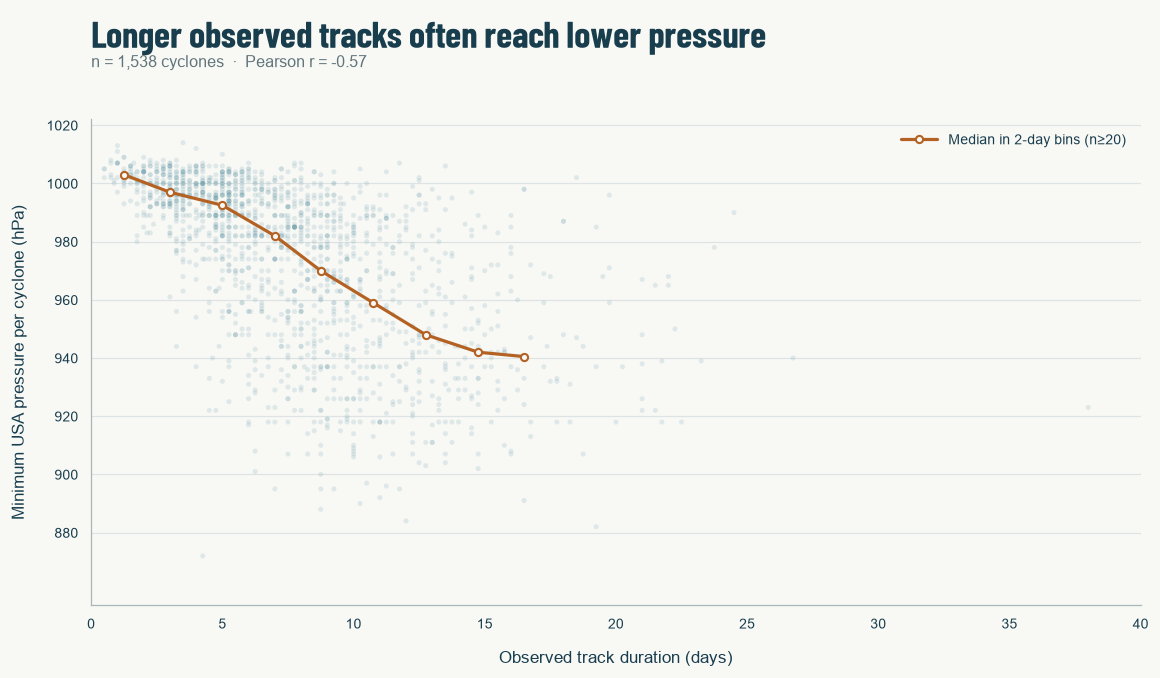

In [6]:
duration_pressure = storm_df[["duration_days","min_pressure"]].dropna()
r_dp = duration_pressure.duration_days.corr(duration_pressure.min_pressure,method="pearson")
pressure_bins = pd.cut(duration_pressure.duration_days,np.arange(0,41,2),right=False)
duration_pressure_trend = duration_pressure.groupby(pressure_bins,observed=True).agg(duration=("duration_days","median"),pressure=("min_pressure","median"),n=("min_pressure","size"))
duration_pressure_trend = duration_pressure_trend.loc[duration_pressure_trend.n>=20]
paper, ink, muted, point, median, grid = (
    "#F8F8F5", "#183D4D", "#60747A", "#4D8B9D", "#B36224", "#D8E0DF"
)
fig, ax = plt.subplots(figsize=(10.8, 6.5), facecolor=paper)
fig.subplots_adjust(left=.115, right=.96, bottom=.16, top=.81)
ax.set_facecolor(paper)

ax.scatter(duration_pressure.duration_days, duration_pressure.min_pressure, s=10, alpha=.14,
           color=point, edgecolors="none", rasterized=True, zorder=2)
ax.plot(duration_pressure_trend.duration, duration_pressure_trend.pressure, color=median,
        linewidth=2, marker="o", markersize=4.5, markerfacecolor=paper,
        markeredgecolor=median, markeredgewidth=1.3,
        label="Median in 2-day bins (n≥20)", zorder=3)

ax.set(xlim=(0, 40), ylim=(855, 1022))
ax.set_xticks(np.arange(0, 41, 5))
ax.set_yticks(np.arange(880, 1021, 20))
ax.set_xlabel("Observed track duration (days)", color=ink, fontsize=10.5, labelpad=12)
ax.set_ylabel("Minimum USA pressure per cyclone (hPa)", color=ink, fontsize=10.5, labelpad=12)
ax.grid(False)
ax.yaxis.grid(True, color=grid, linewidth=.75, alpha=.82)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#A9B9BA")
    ax.spines[spine].set_linewidth(.8)
ax.tick_params(axis="both", which="both", length=0, pad=8,
               labelcolor=ink, labelsize=9)

fig.suptitle("Longer observed tracks often reach lower pressure", x=.115, y=.955, ha="left",
             color=ink, fontsize=23, fontweight="bold", fontfamily="Barlow Condensed")
fig.text(.115, .88, f"n = {len(duration_pressure):,} cyclones  ·  Pearson r = {r_dp:.2f}",
         color=muted, fontsize=10)
ax.legend(loc="upper right", frameon=False, labelcolor=ink,
          fontsize=9, handlelength=2.5, borderaxespad=.6)
plt.show()


Minimum pressure decreases with observed duration (**Pearson r≈−0.57**), consistent with the wind pattern. Both duration relationships show moderate overall linear associations between archive summaries; their binned median trends are not perfectly straight. Missing USA measurements, unequal track lengths, and storms clipped at the dataset boundaries can influence them. The wind and pressure results are not independent pieces of evidence: they reflect closely linked intensity measures.


## 3. How does cyclone intensity vary over time?

Each cyclone is assigned to the year of its **first retained observation**, even if its track crosses New Year. The first chart shows the annual median of storm peak wind and the interquartile range (IQR), which conveys the middle half of the measured storms. This displays intensity, not annual cyclone frequency. The number of wind-measured storms changes by year and affects stability.


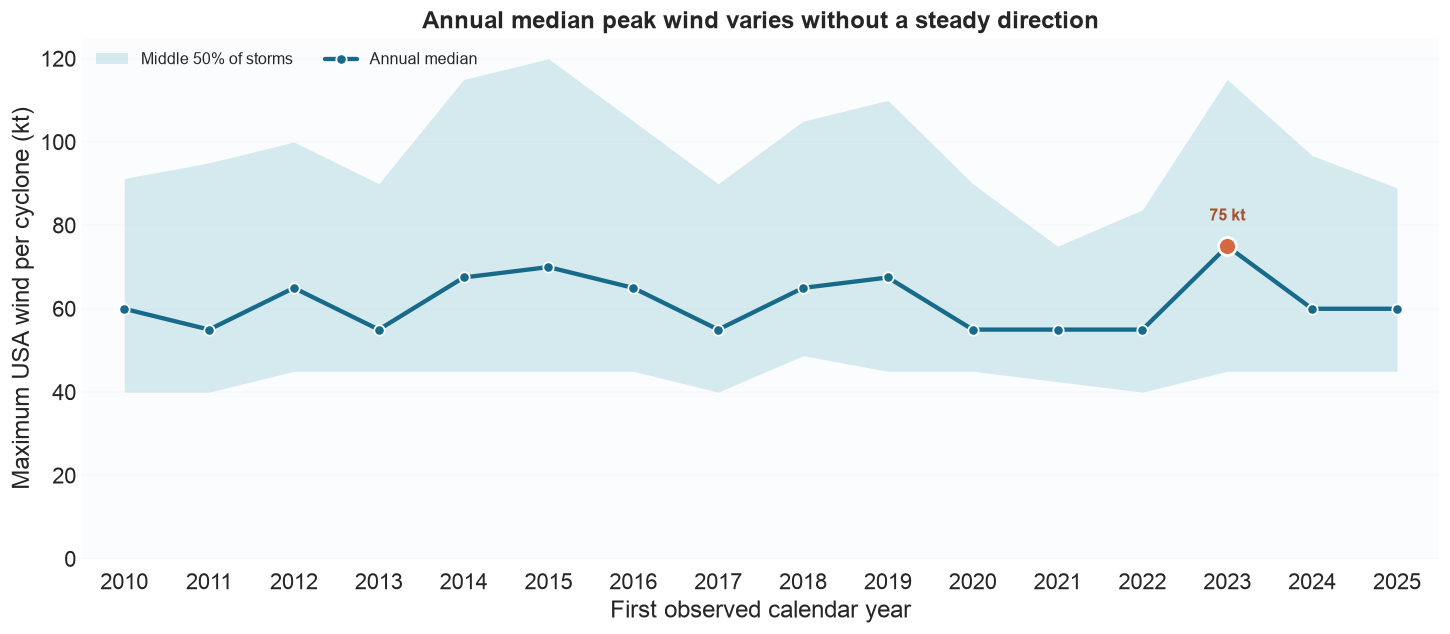

In [8]:
annual = storm_df.groupby("first_year").max_wind.agg(n="count",median="median",q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75),maximum="max")
main_2025_measured = storm_df.loc[(storm_df.first_year.eq(2025)) & storm_df.all_main,"max_wind"].count()
fig, ax = plt.subplots(figsize=(12.5, 5.4), constrained_layout=True)
fig.patch.set_facecolor("white")
ax.set_facecolor("#FBFCFD")
ax.fill_between(annual.index, annual.q25, annual.q75, color="#B9DDE6", alpha=.58,
                linewidth=0, label="Middle 50% of storms", zorder=1)
ax.plot(annual.index, annual["median"], color="#176A8A", linewidth=2.7, marker="o",
        markersize=6.5, markeredgecolor="white", markeredgewidth=1.1,
        label="Annual median", zorder=3)
peak_median_year = annual["median"].idxmax()
ax.scatter(peak_median_year, annual.loc[peak_median_year,"median"], s=125,
           color="#D5683E", edgecolor="white", linewidth=1.7, zorder=5)
ax.annotate(f"{annual.loc[peak_median_year, 'median']:.0f} kt", 
            (peak_median_year, annual.loc[peak_median_year,"median"]),
            xytext=(0, 14), textcoords="offset points", ha="center", va="bottom",
            color="#A94E2D", weight="bold", fontsize=10)
ax.set(title="Annual median peak wind varies without a steady direction",
       xlabel="First observed calendar year", ylabel="Maximum USA wind per cyclone (kt)",
       xlim=(annual.index.min()-.5, annual.index.max()+.5), ylim=(0,125))
ax.set_xticks(annual.index)
ax.tick_params(axis="x", rotation=0, length=0, pad=9)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", color="#E7EDF0", linewidth=1)
ax.grid(axis="x", visible=False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper left", fontsize=10)
plt.show()


Annual medians range from **55 to 75 kt**, with the highest median in **2023**. The broad IQR bands show that storms within the same year differ far more than the smooth annual line might imply. The 2025 cohort includes many provisional or non-main tracks; **106** storms have a USA wind value, but only **33** have exclusively main-track fixes and a USA wind value. These are archive-dependent annual summaries, not evidence of a long-term trend.


Basin-by-year medians show whether global annual summaries conceal different regional histories. A cell is blank when fewer than **eight** storms have a USA wind measurement in that basin and year; a median from such a small set would be especially unstable. The same sequential color scale is used across all basins and years.


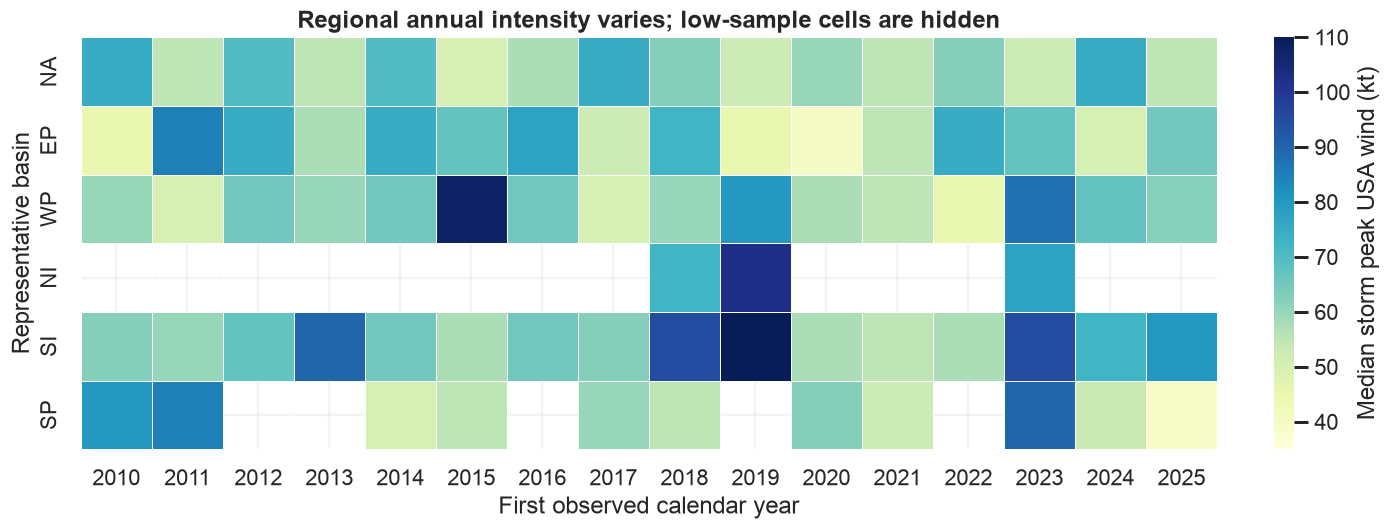

In [9]:
basin_year = storm_df.loc[storm_df.basin.isin(MAJOR_BASINS)].groupby(["basin","first_year"]).max_wind.agg(["median","count"])
median_grid = basin_year["median"].unstack().reindex(MAJOR_BASINS).reindex(columns=annual.index)
count_grid = basin_year["count"].unstack(fill_value=0).reindex(MAJOR_BASINS).reindex(columns=annual.index,fill_value=0)
fig,ax=plt.subplots(figsize=(12,4.5),constrained_layout=True)
sns.heatmap(median_grid,mask=count_grid.lt(8),cmap="YlGnBu",vmin=35,vmax=110,linewidths=.4,linecolor="white",cbar_kws={"label":"Median storm peak USA wind (kt)"},ax=ax)
ax.set(title="Regional annual intensity varies; low-sample cells are hidden",xlabel="First observed calendar year",ylabel="Representative basin")
plt.show()


Regional medians fluctuate rather than moving together. For example, the West Pacific median is relatively high in **2015**, while other basins show their higher-median years at different times. Many North Indian cells are blank because of low USA-wind coverage, so the heatmap cannot support a detailed trend claim for that basin. South Atlantic is omitted entirely because only two storms appear in the full period. The date window also contains **12 storms assigned to meteorological season 2026**; these belong to 2025 by first observed calendar year here, and season 2026 is incomplete.


## Conclusions

**Basin intensity.** The South Indian basin has a higher measured median peak wind and lower median pressure than the North Atlantic, and a larger share of measured storms reaches ≥96 kt. The basin distributions overlap substantially, and measurement coverage is unequal.

**Relationships.** Storm-level peak wind and minimum pressure have a strong inverse association (Pearson r≈−0.97). Observed duration has a moderate linear association with stronger peak wind (r≈0.57) and lower minimum pressure (r≈−0.57). These are relationships between track summaries; wind and pressure extrema may occur at different times. None demonstrates causation.

**Time.** Annual median peak wind, annual extremes, and regional medians vary irregularly from 2010 to 2025. This short window, provisional recent records, uneven measurement coverage, and incomplete boundary seasons do not justify a long-term climate or climate-change conclusion.

All figures use one row per cyclone and preserve `NA` as North Atlantic. USA and WMO winds are not merged. The next scientific step would be to check whether regional intensity comparisons persist with more complete, harmonized measurements and a longer, consistently finalized record.
